# Assignment 4 — Question 1: CIFAR-100 Knowledge Distillation

This single Google Colab notebook trains a CIFAR-100 ResNet-50 teacher, then trains
MobileNetV2, SqueezeNet, and EfficientNet-Lite0 both with knowledge distillation and
as independent cross-entropy baselines. It evaluates every student and exports the
six student models to ONNX for CPU inference with ONNX Runtime.

**Run from top to bottom.** In Colab, select a GPU runtime before starting. Training
is intentionally configurable: use the epoch settings below for a practical run, then
increase them if you have more runtime. Checkpoints and metrics are saved in Drive.



In [1]:
%pip -q install scikit-learn matplotlib pandas onnx onnxruntime tqdm

import copy
import json
import platform
import random
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from tqdm.auto import tqdm

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: Training on CPU will be very slow. Select Runtime > Change runtime type > GPU.")



Python: 3.13.16
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA available: True
GPU: Tesla T4


## 1. Mount Drive and configure the experiment

Set `TEACHER_EPOCHS` and `STUDENT_EPOCHS` before training. Existing complete
checkpoints are reused; incomplete checkpoints resume from their last saved epoch.



In [2]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/KD_CIFAR100_Knowledge_Distillation")
CHECKPOINT_ROOT = PROJECT_ROOT / "03_Checkpoints"
TEACHER_ROOT = CHECKPOINT_ROOT / "teacher"
BASELINE_ROOT = CHECKPOINT_ROOT / "baseline"
DISTILLED_ROOT = CHECKPOINT_ROOT / "distilled"
ONNX_ROOT = PROJECT_ROOT / "04_ONNX_Models" / "fp32"
RESULTS_ROOT = PROJECT_ROOT / "05_Results"
METRICS_ROOT = RESULTS_ROOT / "metrics"
FIGURES_ROOT = RESULTS_ROOT / "figures"
MANIFEST_ROOT = PROJECT_ROOT / "07_Manifests"
DATA_ROOT = PROJECT_ROOT / "data" / "cifar100"

for folder in (
    TEACHER_ROOT, BASELINE_ROOT, DISTILLED_ROOT, ONNX_ROOT,
    METRICS_ROOT, FIGURES_ROOT, MANIFEST_ROOT, DATA_ROOT
):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
BATCH_SIZE = 128
NUM_WORKERS = 2
VAL_FRACTION = 0.10
NUM_CLASSES = 100
TEACHER_EPOCHS = 10
STUDENT_EPOCHS = 10
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
KD_TEMPERATURE = 4.0
KD_ALPHA = 0.7
FEATURE_WEIGHT = 0.1
FORCE_RETRAIN = False

MEAN = (0.5071, 0.4867, 0.4408)
STD = (0.2675, 0.2565, 0.2761)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
torch.backends.cudnn.benchmark = torch.cuda.is_available()

print("Project:", PROJECT_ROOT)
print("Device:", DEVICE, "| Teacher epochs:", TEACHER_EPOCHS, "| Student epochs:", STUDENT_EPOCHS)



Mounted at /content/drive
Project: /content/drive/MyDrive/KD_CIFAR100_Knowledge_Distillation
Device: cuda | Teacher epochs: 10 | Student epochs: 10


## 2. Download CIFAR-100 and create reproducible data loaders

The official test set is never used for training or model selection. A stratified
45,000/5,000 train/validation split is saved so later runs use the same examples.



In [3]:
train_raw = datasets.CIFAR100(root=str(DATA_ROOT), train=True, download=True)
test_raw = datasets.CIFAR100(root=str(DATA_ROOT), train=False, download=True)
class_names = train_raw.classes
targets = np.asarray(train_raw.targets, dtype=np.int64)
test_targets = np.asarray(test_raw.targets, dtype=np.int64)

assert len(train_raw) == 50_000 and len(test_raw) == 10_000
assert len(class_names) == NUM_CLASSES

SPLIT_PATH = MANIFEST_ROOT / f"cifar100_split_seed{SEED}.npz"
if SPLIT_PATH.exists():
    split = np.load(SPLIT_PATH)
    train_idx = split["train_indices"].astype(np.int64)
    val_idx = split["val_indices"].astype(np.int64)
    if int(split["seed"]) != SEED:
        raise ValueError(f"Split seed mismatch in {SPLIT_PATH}")
else:
    train_idx, val_idx = train_test_split(
        np.arange(len(train_raw)),
        test_size=VAL_FRACTION,
        random_state=SEED,
        stratify=targets,
    )
    train_idx = np.asarray(train_idx, dtype=np.int64)
    val_idx = np.asarray(val_idx, dtype=np.int64)
    np.savez_compressed(
        SPLIT_PATH, train_indices=train_idx, val_indices=val_idx, seed=SEED
    )

train_counts = np.bincount(targets[train_idx], minlength=NUM_CLASSES)
val_counts = np.bincount(targets[val_idx], minlength=NUM_CLASSES)
assert len(train_idx) == 45_000 and len(val_idx) == 5_000
assert len(np.intersect1d(train_idx, val_idx)) == 0
assert np.all(train_counts == 450) and np.all(val_counts == 50)
assert np.all(np.bincount(test_targets, minlength=NUM_CLASSES) == 100)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
train_full = datasets.CIFAR100(
    root=str(DATA_ROOT), train=True, download=False, transform=train_transform
)
eval_full = datasets.CIFAR100(
    root=str(DATA_ROOT), train=True, download=False, transform=eval_transform
)
test_dataset = datasets.CIFAR100(
    root=str(DATA_ROOT), train=False, download=False, transform=eval_transform
)
train_dataset = Subset(train_full, train_idx.tolist())
val_dataset = Subset(eval_full, val_idx.tolist())
loader_options = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available(),
}
train_loader = DataLoader(train_dataset, shuffle=True, **loader_options)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)

images, labels = next(iter(train_loader))
assert images.shape[1:] == (3, 32, 32)
assert labels.min().item() >= 0 and labels.max().item() < NUM_CLASSES
assert torch.isfinite(images).all()
print(
    f"Train={len(train_dataset):,}, validation={len(val_dataset):,}, "
    f"test={len(test_dataset):,}; batch={tuple(images.shape)}"
)



100%|██████████| 169M/169M [29:04<00:00, 96.9kB/s]


Train=45,000, validation=5,000, test=10,000; batch=(128, 3, 32, 32)


## 3. Define the teacher and student architectures

EfficientNet-Lite0 is implemented here as a CIFAR-sized Lite-style network: MBConv
blocks with ReLU6 and no squeeze-and-excitation, followed by global pooling. This
avoids relying on external model-zoo packages and keeps the notebook self-contained.



In [4]:
class ResNet50Teacher(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        from torchvision.models import resnet50
        self.net = resnet50(weights=None)
        self.net.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.net.maxpool = nn.Identity()
        self.net.fc = nn.Linear(self.net.fc.in_features, num_classes)
        self.feature_dim = self.net.fc.in_features

    def forward_with_features(self, x):
        net = self.net
        x = net.relu(net.bn1(net.conv1(x)))
        x = net.maxpool(x)
        x = net.layer1(x)
        x = net.layer2(x)
        x = net.layer3(x)
        x = net.layer4(x)
        features = torch.flatten(net.avgpool(x), 1)
        return net.fc(features), features

    def forward(self, x):
        return self.forward_with_features(x)[0]


class MobileNetV2Student(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        from torchvision.models import mobilenet_v2
        self.net = mobilenet_v2(weights=None)
        self.net.classifier[-1] = nn.Linear(self.net.last_channel, num_classes)
        self.feature_dim = self.net.last_channel

    def forward_with_features(self, x):
        x = self.net.features(x)
        features = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.net.classifier(features), features

    def forward(self, x):
        return self.forward_with_features(x)[0]


class SqueezeNetStudent(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        from torchvision.models import squeezenet1_1
        self.features_net = squeezenet1_1(weights=None).features
        self.dropout = nn.Dropout(p=0.5)
        self.classifier = nn.Conv2d(512, num_classes, kernel_size=1)
        self.feature_dim = 512

    def forward_with_features(self, x):
        x = self.features_net(x)
        features = F.adaptive_avg_pool2d(x, 1).flatten(1)
        logits = self.classifier(self.dropout(x))
        logits = F.adaptive_avg_pool2d(logits, 1).flatten(1)
        return logits, features

    def forward(self, x):
        return self.forward_with_features(x)[0]


class ConvBNReLU6(nn.Sequential):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, groups=1):
        padding = (kernel_size - 1) // 2
        super().__init__(
            nn.Conv2d(
                in_channels, out_channels, kernel_size, stride, padding,
                groups=groups, bias=False,
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU6(inplace=True),
        )


class LiteMBConv(nn.Module):
    def __init__(self, in_channels, out_channels, expansion, stride, kernel_size=3):
        super().__init__()
        hidden = in_channels * expansion
        layers = []
        if expansion != 1:
            layers.append(ConvBNReLU6(in_channels, hidden, kernel_size=1))
        layers.append(ConvBNReLU6(
            hidden, hidden, kernel_size=kernel_size, stride=stride, groups=hidden
        ))
        layers.extend([
            nn.Conv2d(hidden, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
        ])
        self.block = nn.Sequential(*layers)
        self.use_residual = stride == 1 and in_channels == out_channels

    def forward(self, x):
        result = self.block(x)
        return x + result if self.use_residual else result


class EfficientNetLite0Student(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.stem = ConvBNReLU6(3, 32, kernel_size=3, stride=2)
        # (expansion, output channels, repeats, first-block stride, kernel size)
        settings = [
            (1, 16, 1, 1, 3),
            (6, 24, 2, 2, 3),
            (6, 40, 2, 2, 5),
            (6, 80, 3, 2, 3),
            (6, 112, 3, 1, 5),
            (6, 192, 4, 2, 5),
            (6, 320, 1, 1, 3),
        ]
        blocks = []
        in_channels = 32
        for expansion, out_channels, repeats, first_stride, kernel_size in settings:
            for block_index in range(repeats):
                stride = first_stride if block_index == 0 else 1
                blocks.append(
                    LiteMBConv(in_channels, out_channels, expansion, stride, kernel_size)
                )
                in_channels = out_channels
        self.blocks = nn.Sequential(*blocks)
        self.head = ConvBNReLU6(in_channels, 1280, kernel_size=1)
        self.classifier = nn.Linear(1280, num_classes)
        self.feature_dim = 1280

    def forward_with_features(self, x):
        x = self.head(self.blocks(self.stem(x)))
        features = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.classifier(features), features

    def forward(self, x):
        return self.forward_with_features(x)[0]


MODEL_BUILDERS = {
    "mobilenet_v2": MobileNetV2Student,
    "squeezenet": SqueezeNetStudent,
    "efficientnet_lite0": EfficientNetLite0Student,
}

def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

for model_name, model_builder in MODEL_BUILDERS.items():
    sample_model = model_builder()
    with torch.no_grad():
        logits, features = sample_model.forward_with_features(torch.randn(2, 3, 32, 32))
    assert logits.shape == (2, NUM_CLASSES)
    assert features.shape == (2, sample_model.feature_dim)
    print(f"{model_name}: {count_parameters(sample_model):,} trainable parameters")
    del sample_model



mobilenet_v2: 2,351,972 trainable parameters
squeezenet: 773,796 trainable parameters
efficientnet_lite0: 3,499,108 trainable parameters


## 4. Training, checkpoints, and metrics

The distillation objective combines hard-label cross-entropy, temperature-scaled
teacher soft targets, and cosine feature matching. A learned linear adapter aligns
each student's pooled feature vector with the teacher's 2,048-dimensional vector.



In [12]:
def load_checkpoint(path):
    return torch.load(path, map_location=DEVICE, weights_only=False)


def save_checkpoint(path, payload):
    path = Path(path)
    temporary_path = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temporary_path)
    temporary_path.replace(path)


@torch.no_grad()
def evaluate_model(model, loader):
    model.eval()
    loss_sum = 0.0
    correct = 0
    total = 0
    criterion = nn.CrossEntropyLoss()
    for inputs, targets_batch in loader:
        inputs = inputs.to(DEVICE, non_blocking=True)
        targets_batch = targets_batch.to(DEVICE, non_blocking=True)
        logits = model(inputs)
        loss_sum += criterion(logits, targets_batch).item() * targets_batch.size(0)
        correct += (logits.argmax(dim=1) == targets_batch).sum().item()
        total += targets_batch.size(0)
    return {"loss": loss_sum / total, "accuracy": correct / total}


def fit_model(
    model,
    train_loader,
    val_loader,
    checkpoint_path,
    run_name,
    epochs,
    teacher=None,
    feature_adapter=None,
):
    model = model.to(DEVICE)
    if teacher is not None:
        teacher = teacher.to(DEVICE).eval()
        for parameter in teacher.parameters():
            parameter.requires_grad_(False)
    if feature_adapter is not None:
        feature_adapter = feature_adapter.to(DEVICE)

    trainable_parameters = list(model.parameters())
    if feature_adapter is not None:
        trainable_parameters += list(feature_adapter.parameters())
    optimizer = torch.optim.AdamW(
        trainable_parameters, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    hard_criterion = nn.CrossEntropyLoss()
    history = []
    start_epoch = 0
    best_accuracy = -1.0
    best_model_state = None
    best_adapter_state = None
    checkpoint_path = Path(checkpoint_path)

    if checkpoint_path.exists() and not FORCE_RETRAIN:
        saved = load_checkpoint(checkpoint_path)
        model.load_state_dict(saved["model_state"])
        if feature_adapter is not None and saved.get("adapter_state") is not None:
            feature_adapter.load_state_dict(saved["adapter_state"])
        if saved.get("complete", False) and saved.get("epochs_completed", 0) >= epochs:
            print(f"Using completed checkpoint: {checkpoint_path.name}")
            return model, feature_adapter, saved.get("history", [])
        if saved.get("optimizer_state") is not None:
            optimizer.load_state_dict(saved["optimizer_state"])
        start_epoch = int(saved.get("epochs_completed", 0))
        best_accuracy = float(saved.get("best_accuracy", -1.0))
        best_model_state = saved.get("best_model_state")
        best_adapter_state = saved.get("best_adapter_state")
        history = saved.get("history", [])
        if start_epoch >= epochs:
            epochs = start_epoch

    for epoch in range(start_epoch, epochs):
        model.train()
        if feature_adapter is not None:
            feature_adapter.train()
        loss_sum = 0.0
        correct = 0
        total = 0
        progress = tqdm(train_loader, desc=f"{run_name} {epoch + 1}/{epochs}", leave=False)
        for inputs, targets_batch in progress:
            inputs = inputs.to(DEVICE, non_blocking=True)
            targets_batch = targets_batch.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            if teacher is None:
                logits = model(inputs)
                loss = hard_criterion(logits, targets_batch)
            else:
                logits, student_features = model.forward_with_features(inputs)
                with torch.no_grad():
                    teacher_logits, teacher_features = teacher.forward_with_features(inputs)
                temperature = KD_TEMPERATURE
                soft_targets = F.softmax(teacher_logits / temperature, dim=1)
                soft_loss = F.kl_div(
                    F.log_softmax(logits / temperature, dim=1),
                    soft_targets,
                    reduction="batchmean",
                ) * (temperature ** 2)
                hard_loss = hard_criterion(logits, targets_batch)
                projected_features = F.normalize(feature_adapter(student_features), dim=1)
                teacher_features = F.normalize(teacher_features, dim=1)
                feature_loss = 1.0 - F.cosine_similarity(
                    projected_features, teacher_features, dim=1
                ).mean()
                loss = (
                    (1.0 - KD_ALPHA) * hard_loss
                    + KD_ALPHA * soft_loss
                    + FEATURE_WEIGHT * feature_loss
                )

            loss.backward()
            optimizer.step()
            batch_size = targets_batch.size(0)
            loss_sum += loss.item() * batch_size
            correct += (logits.detach().argmax(dim=1) == targets_batch).sum().item()
            total += batch_size
            progress.set_postfix(loss=f"{loss.item():.3f}")

        validation = evaluate_model(model, val_loader)
        epoch_metrics = {
            "epoch": epoch + 1,
            "train_loss": loss_sum / total,
            "train_accuracy": correct / total,
            "val_loss": validation["loss"],
            "val_accuracy": validation["accuracy"],
        }
        history.append(epoch_metrics)
        print(
            f"{run_name} epoch {epoch + 1}: "
            f"train_acc={epoch_metrics['train_accuracy']:.4f}, "
            f"val_acc={validation['accuracy']:.4f}"
        )

        if validation["accuracy"] > best_accuracy:
            best_accuracy = validation["accuracy"]
            best_model_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            best_adapter_state = (
                {
                    key: value.detach().cpu().clone()
                    for key, value in feature_adapter.state_dict().items()
                }
                if feature_adapter is not None else None
            )

        save_checkpoint(checkpoint_path, {
            "model_state": model.state_dict(),
            "adapter_state": feature_adapter.state_dict() if feature_adapter is not None else None,
            "optimizer_state": optimizer.state_dict(),
            "epochs_completed": epoch + 1,
            "best_accuracy": best_accuracy,
            "best_model_state": best_model_state,
            "best_adapter_state": best_adapter_state,
            "history": history,
            "complete": False,
        })

    if best_model_state is not None:
        model.load_state_dict(best_model_state)
    if feature_adapter is not None and best_adapter_state is not None:
        feature_adapter.load_state_dict(best_adapter_state)
    save_checkpoint(checkpoint_path, {
        "model_state": model.state_dict(),
        "adapter_state": feature_adapter.state_dict() if feature_adapter is not None else None,
        "optimizer_state": optimizer.state_dict(),
        "epochs_completed": epochs,
        "best_accuracy": best_accuracy,
        "best_model_state": best_model_state,
        "best_adapter_state": best_adapter_state,
        "history": history,
        "complete": True,
    })
    pd.DataFrame(history).to_csv(
        METRICS_ROOT / f"{run_name}_history.csv", index=False
    )
    return model, feature_adapter, history



## 5. Train the ResNet-50 teacher

The CIFAR-adapted ResNet-50 is trained from scratch. Its best validation checkpoint
is then frozen and used to generate soft targets and intermediate features.



In [13]:
teacher, _, teacher_history = fit_model(
    ResNet50Teacher(),
    train_loader,
    val_loader,
    TEACHER_ROOT / "resnet50_cifar100.pt",
    "teacher_resnet50",
    TEACHER_EPOCHS,
)
teacher.eval()
print("Teacher best validation accuracy:", f"{evaluate_model(teacher, val_loader)['accuracy']:.4f}")



Using completed checkpoint: resnet50_cifar100.pt
Teacher best validation accuracy: 0.5780


## 6. Train all students: baselines and distillation

Each architecture is trained twice on the same train/validation split: first as a
normal supervised baseline, then with the frozen teacher. The feature adapter is
only an auxiliary training head and is not required for inference.



In [7]:
student_models = {}
student_histories = {}

for model_name, model_builder in MODEL_BUILDERS.items():
    print(f"\n===== {model_name}: supervised baseline =====")
    baseline_model, _, baseline_history = fit_model(
        model_builder(),
        train_loader,
        val_loader,
        BASELINE_ROOT / f"{model_name}_baseline.pt",
        f"{model_name}_baseline",
        STUDENT_EPOCHS,
    )
    student_models[f"{model_name}_baseline"] = baseline_model.eval()
    student_histories[f"{model_name}_baseline"] = baseline_history

    print(f"\n===== {model_name}: knowledge distillation =====")
    distilled_model = model_builder()
    adapter = nn.Linear(distilled_model.feature_dim, teacher.feature_dim)
    distilled_model, adapter, distilled_history = fit_model(
        distilled_model,
        train_loader,
        val_loader,
        DISTILLED_ROOT / f"{model_name}_distilled.pt",
        f"{model_name}_distilled",
        STUDENT_EPOCHS,
        teacher=teacher,
        feature_adapter=adapter,
    )
    student_models[f"{model_name}_distilled"] = distilled_model.eval()
    student_histories[f"{model_name}_distilled"] = distilled_history

print("Student training complete:", ", ".join(student_models))




===== mobilenet_v2: supervised baseline =====


mobilenet_v2_baseline 1/10:   0%|          | 0/352 [00:00<?, ?it/s]

mobilenet_v2_baseline epoch 1: train_acc=0.0427, val_acc=0.0700


mobilenet_v2_baseline 2/10:   0%|          | 0/352 [00:00<?, ?it/s]

mobilenet_v2_baseline epoch 2: train_acc=0.0897, val_acc=0.1106


mobilenet_v2_baseline 3/10:   0%|          | 0/352 [00:00<?, ?it/s]

... (127 outputs left out)

efficientnet_lite0_distilled 9/10:   0%|          | 0/352 [00:00<?, ?it/s]

efficientnet_lite0_distilled epoch 9: train_acc=0.2816, val_acc=0.3010


efficientnet_lite0_distilled 10/10:   0%|          | 0/352 [00:00<?, ?it/s]

efficientnet_lite0_distilled epoch 10: train_acc=0.3003, val_acc=0.3156
Student training complete: mobilenet_v2_baseline, mobilenet_v2_distilled, squeezenet_baseline, squeezenet_distilled, efficientnet_lite0_baseline, efficientnet_lite0_distilled


## 7. Test evaluation and unified PyTorch inference

Evaluate the six student checkpoints once on the held-out test set. `predict_topk`
provides a single interface for all PyTorch student models.



In [8]:
@torch.inference_mode()
def predict_topk(model, inputs, k=5):
    model.eval()
    logits = model(inputs.to(DEVICE))
    probabilities = F.softmax(logits, dim=1)
    scores, indices = probabilities.topk(k=min(k, probabilities.shape[1]), dim=1)
    return indices.cpu(), scores.cpu()


test_rows = []
for run_name, model in student_models.items():
    metrics = evaluate_model(model, test_loader)
    test_rows.append({
        "model": run_name,
        "test_loss": metrics["loss"],
        "test_accuracy": metrics["accuracy"],
        "parameters": count_parameters(model),
        "checkpoint": str(
            (DISTILLED_ROOT if run_name.endswith("_distilled") else BASELINE_ROOT)
            / f"{run_name.rsplit('_', 1)[0]}_{'distilled' if run_name.endswith('_distilled') else 'baseline'}.pt"
        ),
    })
    print(f"{run_name}: test accuracy={metrics['accuracy']:.4f}")

test_results = pd.DataFrame(test_rows).sort_values("test_accuracy", ascending=False)
test_results.to_csv(METRICS_ROOT / "student_test_results.csv", index=False)
display(test_results)



mobilenet_v2_baseline: test accuracy=0.2614
mobilenet_v2_distilled: test accuracy=0.3088
squeezenet_baseline: test accuracy=0.1402
squeezenet_distilled: test accuracy=0.1770
efficientnet_lite0_baseline: test accuracy=0.2534
efficientnet_lite0_distilled: test accuracy=0.3223


,model,test_loss,test_accuracy,parameters,checkpoint
5,efficientnet_lite0_distilled,2.849883,0.3223,3499108,/content/drive/MyDrive/KD_CIFAR100_Knowledge_D...
1,mobilenet_v2_distilled,2.931284,0.3088,2351972,/content/drive/MyDrive/KD_CIFAR100_Knowledge_D...
0,mobilenet_v2_baseline,2.933092,0.2614,2351972,/content/drive/MyDrive/KD_CIFAR100_Knowledge_D...
4,efficientnet_lite0_baseline,2.945881,0.2534,3499108,/content/drive/MyDrive/KD_CIFAR100_Knowledge_D...
3,squeezenet_distilled,3.512406,0.1770,773796,/content/drive/MyDrive/KD_CIFAR100_Knowledge_D...
2,squeezenet_baseline,3.537158,0.1402,773796,/content/drive/MyDrive/KD_CIFAR100_Knowledge_D...


## 8. Export all student models to ONNX and verify CPU inference

Exports use a dynamic batch dimension. Each exported graph is loaded by ONNX Runtime
with the CPU execution provider and compared against the PyTorch output on a sample
batch. Latency and file size are recorded for the technical report.



In [9]:
import onnx
import onnxruntime as ort

assert "CPUExecutionProvider" in ort.get_available_providers()
onnx_rows = []
sample_inputs, _ = next(iter(val_loader))
sample_inputs = sample_inputs[:8].to(DEVICE)

for run_name, model in student_models.items():
    model = model.to(DEVICE).eval()
    onnx_path = ONNX_ROOT / f"{run_name}.onnx"
    torch.onnx.export(
        model,
        sample_inputs[:1],
        str(onnx_path),
        input_names=["images"],
        output_names=["logits"],
        dynamic_axes={"images": {0: "batch"}, "logits": {0: "batch"}},
        opset_version=17,
        dynamo=False,
    )
    onnx.checker.check_model(onnx.load(str(onnx_path)))
    session = ort.InferenceSession(
        str(onnx_path), providers=["CPUExecutionProvider"]
    )

    cpu_inputs = sample_inputs.detach().cpu().numpy()
    torch_logits = model(sample_inputs).detach().cpu().numpy()
    ort_logits = session.run(["logits"], {"images": cpu_inputs})[0]
    max_abs_error = float(np.max(np.abs(torch_logits - ort_logits)))
    assert np.allclose(torch_logits, ort_logits, rtol=1e-3, atol=1e-4), (
        f"ONNX output mismatch for {run_name}; max_abs_error={max_abs_error}"
    )

    for _ in range(3):
        session.run(["logits"], {"images": cpu_inputs})
    repetitions = 20
    start_time = time.perf_counter()
    for _ in range(repetitions):
        session.run(["logits"], {"images": cpu_inputs})
    latency_ms = (time.perf_counter() - start_time) * 1000 / repetitions
    onnx_rows.append({
        "model": run_name,
        "onnx_path": str(onnx_path),
        "size_mb": onnx_path.stat().st_size / (1024 ** 2),
        "cpu_latency_ms_per_batch": latency_ms,
        "batch_size": len(cpu_inputs),
        "max_abs_logit_error": max_abs_error,
    })
    print(
        f"{run_name}: ONNX verified; size={onnx_rows[-1]['size_mb']:.2f} MB, "
        f"CPU latency={latency_ms:.2f} ms/batch"
    )

onnx_results = pd.DataFrame(onnx_rows)
onnx_results.to_csv(METRICS_ROOT / "onnx_cpu_benchmarks.csv", index=False)
display(onnx_results)



/tmp/ipykernel_437/2490090439.py:12: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


mobilenet_v2_baseline: ONNX verified; size=8.95 MB, CPU latency=3.38 ms/batch
mobilenet_v2_distilled: ONNX verified; size=8.95 MB, CPU latency=3.43 ms/batch
squeezenet_baseline: ONNX verified; size=2.97 MB, CPU latency=0.79 ms/batch
squeezenet_distilled: ONNX verified; size=2.97 MB, CPU latency=0.79 ms/batch
efficientnet_lite0_baseline: ONNX verified; size=13.30 MB, CPU latency=4.46 ms/batch
efficientnet_lite0_distilled: ONNX verified; size=13.30 MB, CPU latency=6.79 ms/batch


,model,onnx_path,size_mb,cpu_latency_ms_per_batch,batch_size,max_abs_logit_error
0,mobilenet_v2_baseline,/content/drive/MyDrive/KD_CIFAR100_Knowledge_D...,8.946117,3.383881,8,0.000004
1,mobilenet_v2_distilled,/content/drive/MyDrive/KD_CIFAR100_Knowledge_D...,8.946117,3.425997,8,0.000006
2,squeezenet_baseline,/content/drive/MyDrive/KD_CIFAR100_Knowledge_D...,2.968954,0.787678,8,0.000002
3,squeezenet_distilled,/content/drive/MyDrive/KD_CIFAR100_Knowledge_D...,2.968954,0.793051,8,0.000007
4,efficientnet_lite0_baseline,/content/drive/MyDrive/KD_CIFAR100_Knowledge_D...,13.303592,4.458202,8,0.000004
5,efficientnet_lite0_distilled,/content/drive/MyDrive/KD_CIFAR100_Knowledge_D...,13.303592,6.787184,8,0.000005


## 9. Unified ONNX inference helper

This helper accepts a model name and a normalized NumPy batch with shape
`[batch, 3, 32, 32]`, returning top-k CIFAR-100 class names and probabilities.



In [10]:
def create_onnx_predictor(model_name):
    model_path = ONNX_ROOT / f"{model_name}.onnx"
    if not model_path.exists():
        raise FileNotFoundError(f"ONNX model not found: {model_path}")
    session = ort.InferenceSession(
        str(model_path), providers=["CPUExecutionProvider"]
    )

    def predict(batch, k=5):
        batch = np.asarray(batch, dtype=np.float32)
        if batch.ndim != 4 or batch.shape[1:] != (3, 32, 32):
            raise ValueError("Expected normalized input with shape [batch, 3, 32, 32].")
        logits = session.run(["logits"], {"images": batch})[0]
        logits = logits - logits.max(axis=1, keepdims=True)
        probabilities = np.exp(logits)
        probabilities /= probabilities.sum(axis=1, keepdims=True)
        top_indices = np.argsort(probabilities, axis=1)[:, -k:][:, ::-1]
        return [
            [(class_names[index], float(probabilities[row, index])) for index in row_indices]
            for row, row_indices in enumerate(top_indices)
        ]

    return predict


example_model_name = onnx_results.iloc[0]["model"]
onnx_predict = create_onnx_predictor(example_model_name)
example_predictions = onnx_predict(sample_inputs[:2].detach().cpu().numpy(), k=3)
print(example_model_name, "top-3 predictions:", example_predictions[0])



mobilenet_v2_baseline top-3 predictions: [('girl', 0.15313950181007385), ('woman', 0.09788748621940613), ('baby', 0.0639926940202713)]


## 10. Save experiment manifest, plots, and completion checks

The generated CSV files, checkpoints, and ONNX artifacts in Drive are the experimental
outputs to use when preparing the report. Do not report benchmark values until the
notebook has completed successfully on the target Colab runtime.



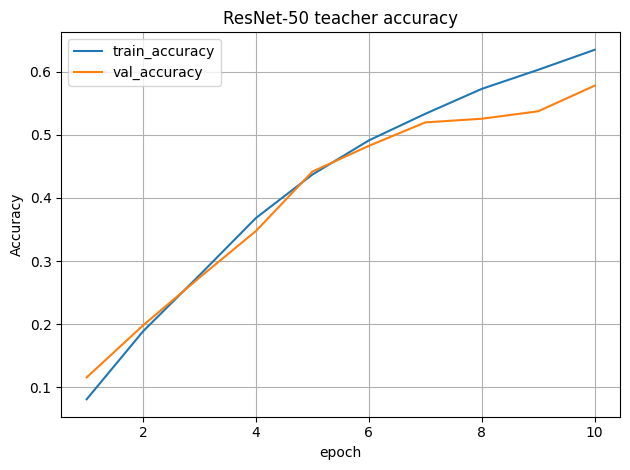

[PASS] CIFAR-100 split
[PASS] Teacher checkpoint
[PASS] Three baselines
[PASS] Three distilled students
[PASS] Six test evaluations
[PASS] Six verified ONNX models
[PASS] ONNX CPU provider

QUESTION 1 COMPLETE
Test results: /content/drive/MyDrive/KD_CIFAR100_Knowledge_Distillation/05_Results/metrics/student_test_results.csv
ONNX CPU benchmarks: /content/drive/MyDrive/KD_CIFAR100_Knowledge_Distillation/05_Results/metrics/onnx_cpu_benchmarks.csv


In [11]:
manifest = {
    "assignment": "A4 Q1 - CIFAR-100 Knowledge Distillation",
    "seed": SEED,
    "dataset": "CIFAR-100",
    "train_size": len(train_dataset),
    "validation_size": len(val_dataset),
    "test_size": len(test_dataset),
    "class_names": class_names,
    "normalization": {"mean": list(MEAN), "std": list(STD)},
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "python": sys.version,
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "teacher_epochs": TEACHER_EPOCHS,
    "student_epochs": STUDENT_EPOCHS,
    "distillation": {
        "temperature": KD_TEMPERATURE,
        "soft_target_weight": KD_ALPHA,
        "feature_weight": FEATURE_WEIGHT,
    },
    "models": list(student_models),
}
with open(MANIFEST_ROOT / "q1_experiment_manifest.json", "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2)

if teacher_history:
    pd.DataFrame(teacher_history).plot(x="epoch", y=["train_accuracy", "val_accuracy"])
    plt.title("ResNet-50 teacher accuracy")
    plt.ylabel("Accuracy")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(FIGURES_ROOT / "teacher_accuracy.png", dpi=150)
    plt.show()

checks = {
    "CIFAR-100 split": len(train_dataset) == 45_000 and len(val_dataset) == 5_000,
    "Teacher checkpoint": (TEACHER_ROOT / "resnet50_cifar100.pt").exists(),
    "Three baselines": all(
        (BASELINE_ROOT / f"{name}_baseline.pt").exists()
        for name in MODEL_BUILDERS
    ),
    "Three distilled students": all(
        (DISTILLED_ROOT / f"{name}_distilled.pt").exists()
        for name in MODEL_BUILDERS
    ),
    "Six test evaluations": len(test_results) == 6,
    "Six verified ONNX models": len(onnx_results) == 6
        and all((ONNX_ROOT / f"{name}.onnx").exists() for name in student_models),
    "ONNX CPU provider": "CPUExecutionProvider" in ort.get_available_providers(),
}
for check_name, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {check_name}")
if not all(checks.values()):
    raise RuntimeError("Q1 is incomplete; review the failed checks above.")

print("\nQUESTION 1 COMPLETE")
print("Test results:", METRICS_ROOT / "student_test_results.csv")
print("ONNX CPU benchmarks:", METRICS_ROOT / "onnx_cpu_benchmarks.csv")
